In [50]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np 
import openpyxl

In [51]:
df = pd.read_excel('/Users/ypragnesh/Desktop/Forest-Ecology/Wet_Indices_Percentage_Only.xlsx',sheet_name='FCD')

In [52]:
df.head(5)

,YEAR,NO FOREST,VERY LOW,LOW,MOD. LOW,MODERATE,HIGH
0,1995,1.81,1.72,7.33,15.57,30.12,43.46
1,1996,1.83,0.54,11.11,26.01,34.86,25.65
2,1999,1.77,0.62,7.76,22.58,35.06,32.21
3,2000,0.17,0.67,6.52,22.87,38.07,31.71
4,2001,1.72,0.57,6.07,21.44,37.07,33.13


In [53]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   YEAR       21 non-null     int64  
 1   NO FOREST  21 non-null     float64
 2   VERY LOW   21 non-null     float64
 3   LOW        21 non-null     float64
 4   MOD. LOW   21 non-null     float64
 5   MODERATE   21 non-null     float64
 6   HIGH       21 non-null     float64
dtypes: float64(6), int64(1)
memory usage: 1.3 KB


In [54]:
df.columns

Index(['YEAR', 'NO FOREST', 'VERY LOW', 'LOW', 'MOD. LOW', 'MODERATE', 'HIGH'],
      dtype='str')

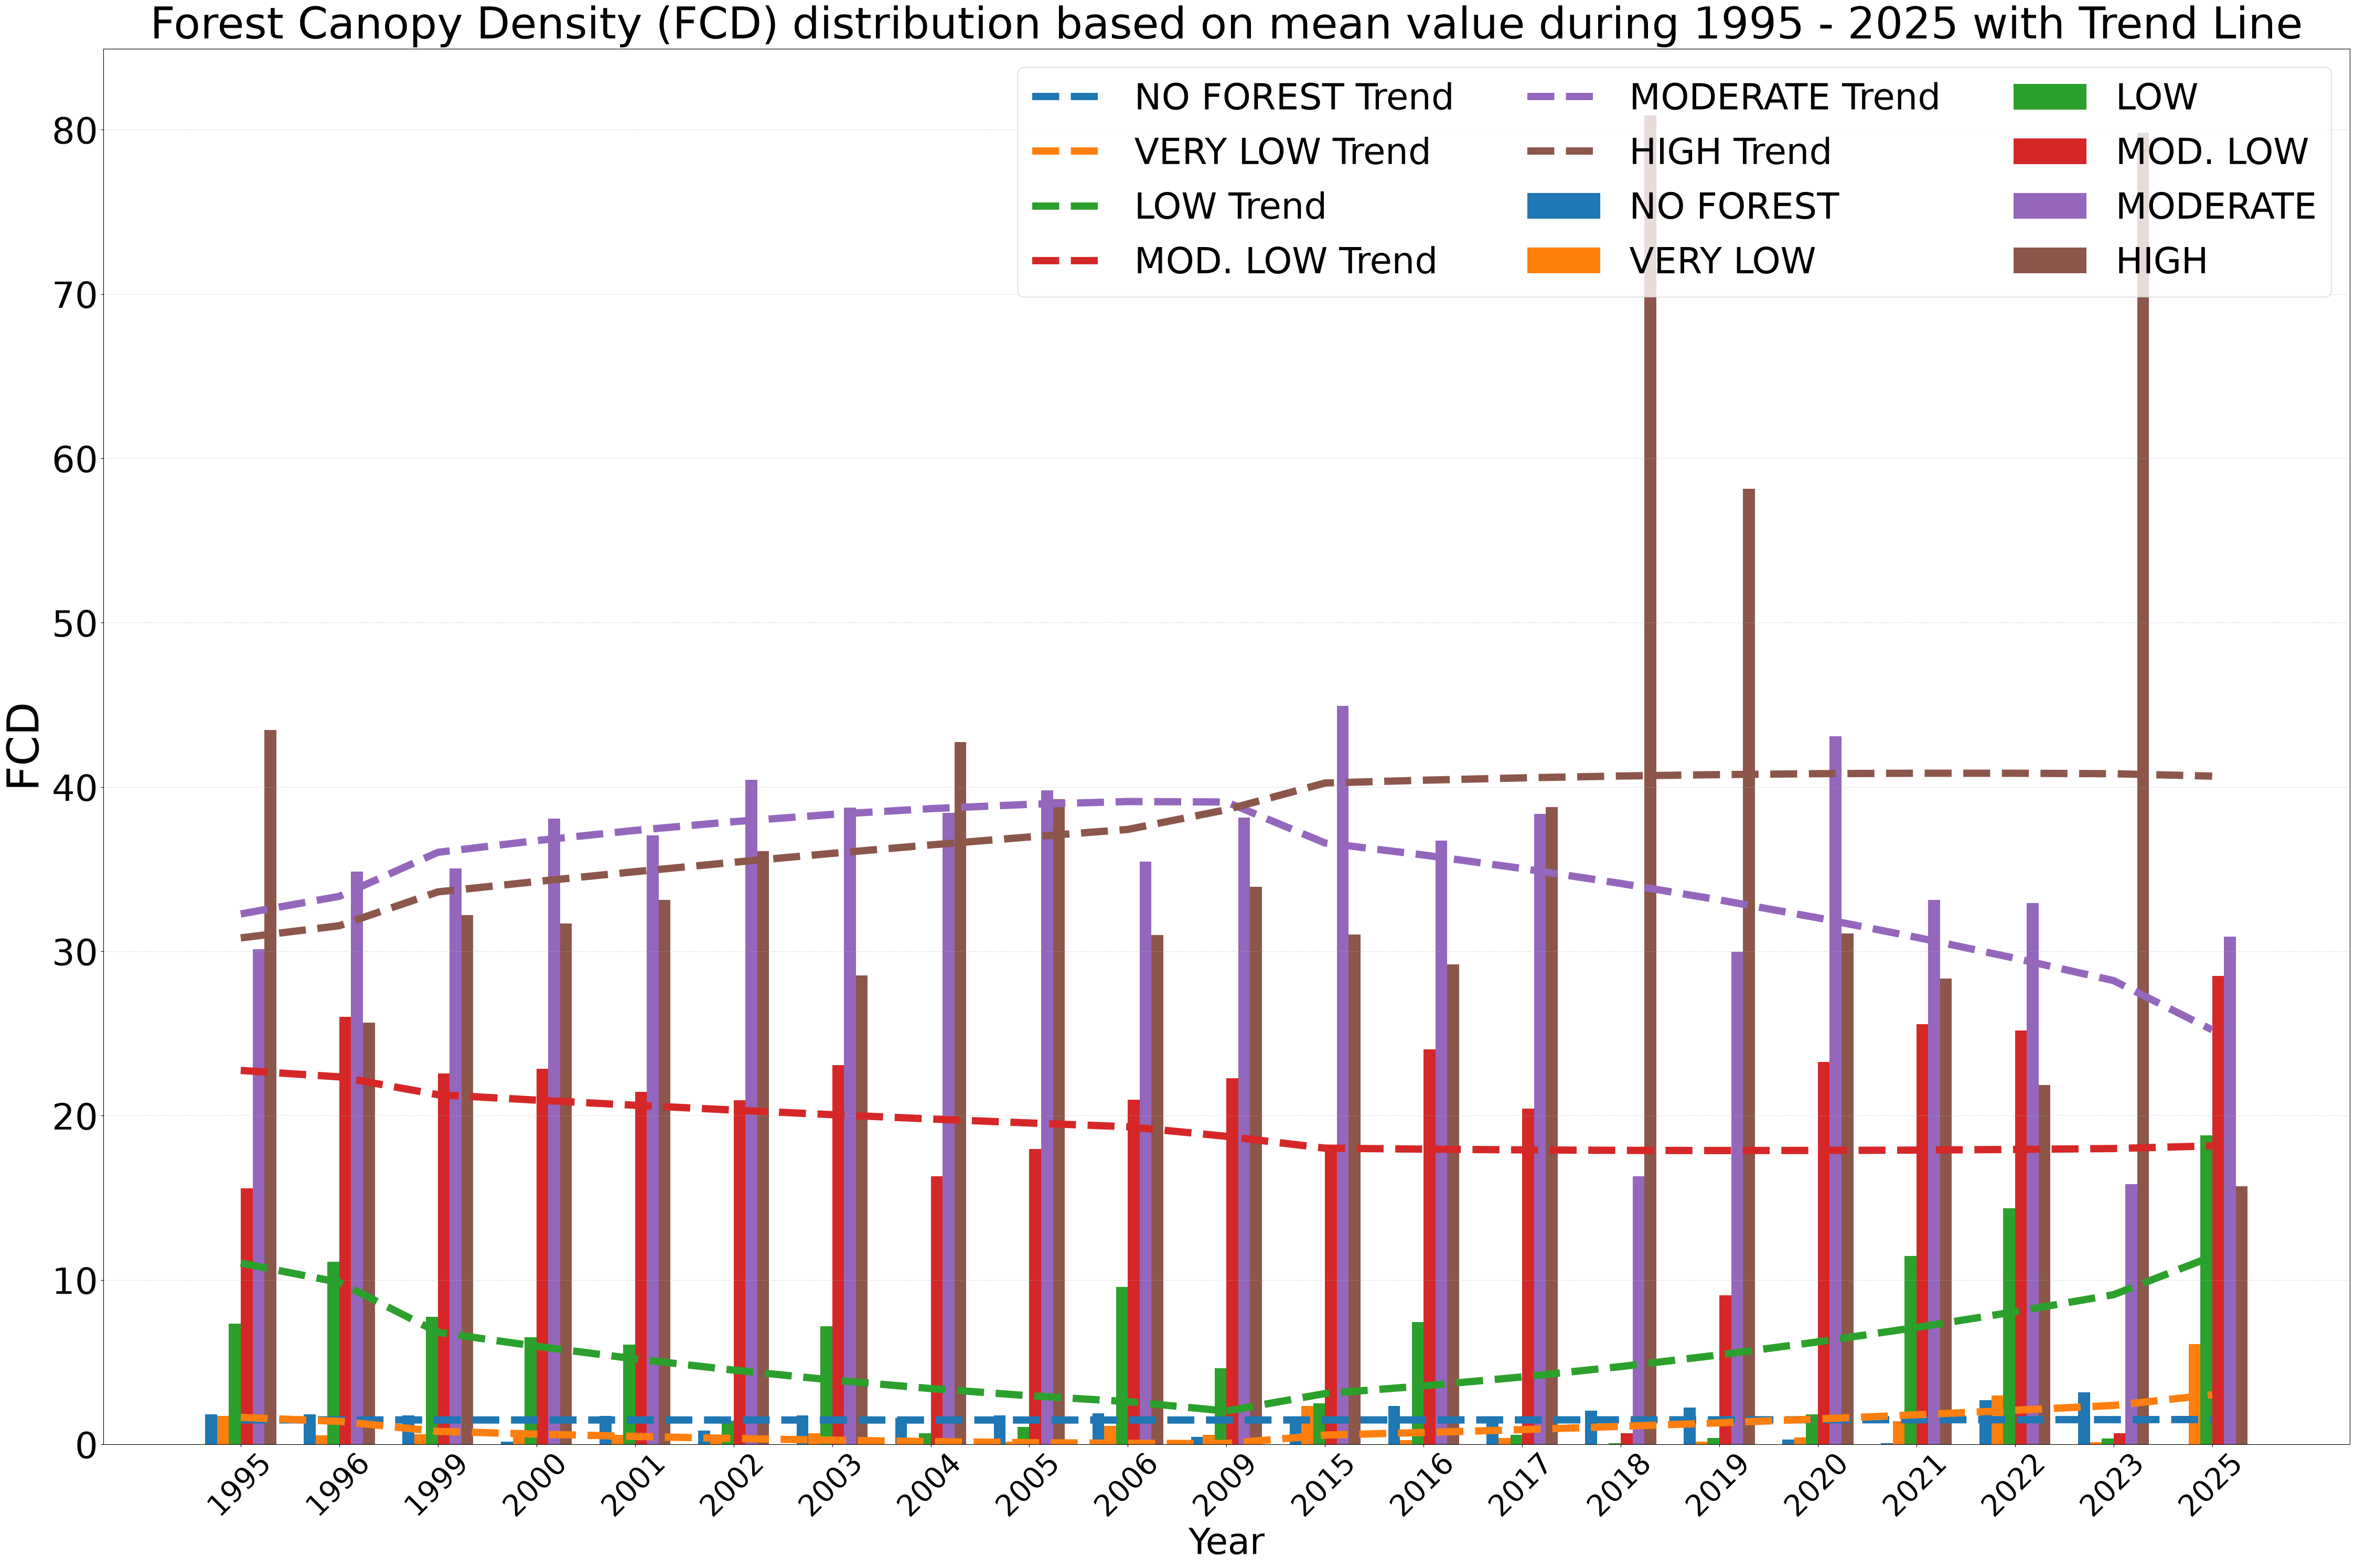

<Figure size 640x480 with 0 Axes>

In [55]:
# Work on a copy of the DataFrame
df = df.copy()

# Remove Month because the analysis is yearly
df["YEAR"] = pd.to_numeric(df["YEAR"], errors="coerce")

# Actual FCD classes in your dataset
cols = [
'NO FOREST', 'VERY LOW', 'LOW', 'MOD. LOW', 'MODERATE', 'HIGH'
]

# Convert FCD columns to numeric
for col in cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove rows with missing Year values
df = df.dropna(subset=["YEAR"])

# Calculate yearly mean for each FCD class
df = df.groupby("YEAR", as_index=False)[cols].mean()
df = df.sort_values("YEAR").reset_index(drop=True)

# Use actual years for trendline fitting
years = df["YEAR"].to_numpy(dtype=float)

plt.figure(figsize=(45, 30))

width = 0.12
x = np.arange(len(df))

# Plot bars
for i, col in enumerate(cols):
    plt.bar(
        x + (i - 2.5) * width,
        df[col],
        width,
        label=col
    )

# Plot quadratic trendlines
for col in cols:
    y = df[col].to_numpy(dtype=float)
    valid = np.isfinite(years) & np.isfinite(y)

    if valid.sum() >= 3:
        z = np.polyfit(years[valid], y[valid], 2)
        p = np.poly1d(z)

        plt.plot(
            x,
            p(years),
            linestyle="--",
            linewidth=10,
            label=f"{col} Trend"
        )
'''
plt.xticks(x, df["Year"].astype(int), rotation=45, fontsize=40)
plt.xlabel("Year", fontsize=50)
plt.ylabel("FCD Value", fontsize=50)
'''

#plt.xticks(x, years,fontsize=50)
plt.xticks(x, df["YEAR"].astype(int), rotation=45, fontsize=40)
plt.yticks(fontsize=50)
plt.xlabel("Year",fontsize=50)
plt.ylabel('FCD',fontsize=60)

plt.title("Forest Canopy Density (FCD) distribution based on mean value during 1995 - 2025 with Trend Line",fontsize=60)

plt.legend(ncol=3,fontsize=50,loc='upper right')
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()
plt.savefig('/Users/ypragnesh/Desktop/fcd/Prem singh/FCD_WET.png')
